# 06 — Results of the experiment

**Question:** are the tracks chosen by the MILP skipped less often than tracks chosen without the predictions, under the same constraints? (`docs/experiment_protocol.md`)

**Data:** a new export of the streaming history and the weekly playlists of `src/experiment.py`; the experimental plays found by `experiment_plays` (runs of at least 3 plays of the active playlist in the same session), resumed plays excluded.

**Metric:** skip rate per arm (`fwdbtn` against `trackdone`, as in the model), with difference and odds ratio, 95% intervals from a bootstrap over sessions, and a one-sided permutation test with the arm labels permuted within each session.

**Dry run.** Until the end of the experiment this notebook runs on a simulated export (`src/simulate_history.py`: the real history plus 13 invented weeks, true odds ratio 0.5), so that the whole analysis is written and checked before any real outcome. The numbers below are not results. The notebook is not run on the real export before the stopping rule of the protocol is met.

In [1]:
import sys

import matplotlib.pyplot as plt
import pandas as pd

sys.path.append("../src")
from analysis import (
    SEED, TARGET_PLAYS, add_arm, bootstrap_ci, effect, experiment_plays, load_playlists,
    permutation_test, secondary,
)
from features import ROOT, build_features
from load_data import clean, load_raw

# Dry run on the simulated export (src/simulate_history.py). At the end of the experiment: the
# folder of the new export, data/experiment and results/experiment.png
EXPORT_DIR = ROOT / "data" / "simulated" / "export"
PLAYLIST_DIR = ROOT / "data" / "simulated" / "experiment"
FIGURE = ROOT / "data" / "experiment_dry_run.png"

# Same cleaning, label and features as the model, then the arm and the experimental plays
df = build_features(clean(load_raw(EXPORT_DIR)))
playlists = load_playlists(PLAYLIST_DIR)
df = add_arm(df, playlists)
df["experimental"] = experiment_plays(df, playlists)
plays = df[df["experimental"] & ~df["resume"]]
labeled = plays[plays["labeled"]]

Files found: 15
Rows loaded: 119408
Removed (not music): 178
Removed (duplicates): 230
Removed (before 2020): 3874


## Experimental plays

In [2]:
# Experimental plays per weekly playlist (the only output allowed before the stop)
weeks = plays.groupby("uploaded").agg(
    plays=("y", "size"), labeled=("labeled", "sum"), sessions=("session_id", "nunique")
)
# Plays of tracks of the active playlist outside a run of 3: free listening that meets the
# playlist by chance, or short visits to it. Not counted
outside = experiment_plays(df, playlists, min_run=1) & ~df["experimental"] & ~df["resume"]
weeks["outside_runs"] = df[outside].groupby("uploaded").size().reindex(weeks.index, fill_value=0)
weeks.index = weeks.index.tz_convert("Europe/Berlin").strftime("%Y-%m-%d")
print(f"Labeled experimental plays: {len(labeled):,} (stopping rule: {TARGET_PLAYS:,})")
weeks

Labeled experimental plays: 1,742 (stopping rule: 1,700)


,plays,labeled,sessions,outside_runs
uploaded,,,,
2026-10-26,142,139,7,9
2026-11-02,158,147,7,10
2026-11-09,142,135,7,13
2026-11-16,144,137,7,9
2026-11-23,125,122,7,4
2026-11-30,132,124,7,4
2026-12-07,144,138,7,4
2026-12-14,137,132,7,11
2026-12-21,139,133,7,6


## Balance between the arms

In [3]:
# Before the outcomes: the arms should differ only in the predicted skip probability p0
balance = plays.groupby("arm").agg(
    plays=("y", "size"), labeled=("labeled", "sum"), sessions=("session_id", "nunique"),
    minutes=("ms_played", lambda ms: ms.sum() / 60_000), mean_p0=("p0", "mean"),
    new_share=("is_new", lambda new: new.astype(bool).mean()),
)
odds = balance["mean_p0"] / (1 - balance["mean_p0"])
print(f"Predicted odds ratio of the plays, MILP over control: {odds['milp'] / odds['control']:.3f}")

# The test compares the arms within sessions: share of the labeled plays in sessions with both
arms_per_session = labeled.groupby("session_id")["arm"].nunique()
both_arms = labeled["session_id"].map(arms_per_session).eq(2).mean()
print(f"Labeled plays in sessions with both arms: {both_arms:.1%}")
balance.round(3)

Predicted odds ratio of the plays, MILP over control: 0.504
Labeled plays in sessions with both arms: 100.0%


,plays,labeled,sessions,minutes,mean_p0,new_share
arm,,,,,,
control,852,818,91,2573.670,0.087,0.134
milp,983,924,91,2787.968,0.046,0.279


## Primary metric

In [4]:
# Skip rate per arm, difference and odds ratio, with 95% intervals from the bootstrap over sessions
y = labeled["y"].to_numpy()
milp = labeled["arm"].eq("milp").to_numpy()
session = labeled["session_id"].to_numpy()
estimate = effect(y[~milp].mean(), y[milp].mean())
table = pd.DataFrame({"estimate": estimate}).join(bootstrap_ci(y, milp, session, rng=SEED))

# One-sided permutation test, arm labels permuted within each session (10,000 permutations)
observed, p_value = permutation_test(y, milp, session, rng=SEED)
print(f"Permutation test: difference {observed:.4f}, one-sided p-value {p_value:.4f}")
table.round(4)

Permutation test: difference 0.0281, one-sided p-value 0.0016


,estimate,ci_low,ci_high
control,0.0465,0.0304,0.0637
milp,0.0184,0.0089,0.0294
difference,0.0281,0.0089,0.0483
odds_ratio,0.3847,0.1743,0.7374


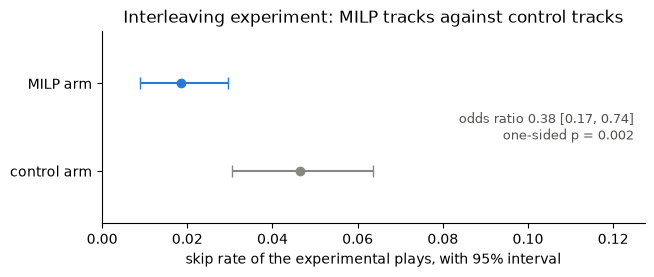

In [5]:
fig, ax = plt.subplots(figsize=(7, 2.5))
for i, (arm, color) in enumerate([("control", "#898781"), ("milp", "#2a78d6")]):
    rate, low, high = table.loc[arm]
    ax.errorbar(rate, i, xerr=[[rate - low], [high - rate]], fmt="o", color=color, capsize=4)
odds_ratio, low, high = table.loc["odds_ratio"]
ax.text(
    0.98, 0.5, f"odds ratio {odds_ratio:.2f} [{low:.2f}, {high:.2f}]\none-sided p = {p_value:.3f}",
    transform=ax.transAxes, ha="right", va="center", color="#52514e", fontsize=9,
)
ax.set_yticks([0, 1], ["control arm", "MILP arm"])
ax.set_ylim(-0.6, 1.6)
ax.set_xlim(0, 2 * table.loc["control", "ci_high"])
ax.set_xlabel("skip rate of the experimental plays, with 95% interval")
ax.set_title("Interleaving experiment: MILP tracks against control tracks")
ax.spines[["top", "right"]].set_visible(False)
fig.savefig(FIGURE, dpi=150, bbox_inches="tight")
plt.show()

## Secondary results

In [6]:
# Descriptive results of the protocol, no test
secondary(plays).round(3).T

arm,control,milp
plays,837.000,967.000
labeled,818.000,924.000
skip_rate,0.046,0.018
fraction_listened,0.941,0.950
endplay_share,0.023,0.044
skip_after_no_skip,0.044,0.015
skip_known,0.051,0.015
skip_new,0.019,0.027


In [7]:
# Not in the protocol, descriptive: predicted p0 against the observed skip rate after a
# non-skipped track (the situation p0 describes), per arm
after_no_skip = labeled[labeled["prev_y"] == 0]
check = after_no_skip.groupby("arm").agg(
    plays=("y", "size"), predicted=("p0", "mean"), observed=("y", "mean")
)
odds = check[["predicted", "observed"]] / (1 - check[["predicted", "observed"]])
print((odds.loc["milp"] / odds.loc["control"]).round(3).rename("odds ratio").to_string())
check.round(3)

predicted    0.500
observed     0.327


,plays,predicted,observed
arm,,,
control,709,0.088,0.044
milp,815,0.046,0.015


## Conclusions

**Dry run on a simulated export: these numbers check the analysis, they are not results.** At the end of the experiment the three paths in the first code cell point to the new export, `data/experiment` and `results/experiment.png`, the notebook is run once, and these conclusions are rewritten with the real numbers.

- **Experimental plays.** 13 simulated weeks give 1,742 labeled experimental plays (stopping rule: 1,700). Every simulated session on the playlist is found (7 a week, one per day), while 4 to 13 plays a week of playlist tracks outside a run of 3 (free listening that meets the playlist by chance) are left out, as the rule intends.
- **Balance between the arms.** The predicted odds ratio of the played tracks is 0.504, as planned (0.51 in notebook 05), and 100.0% of the labeled plays are in sessions with both arms, so the comparison within sessions uses all of them. The MILP arm has more new tracks, 27.9% against 13.4%, within the same limits (see the protocol).
- **Primary metric.** Skip rate 4.65% in the control arm and 1.84% in the MILP arm: difference 2.81 points [0.89, 4.83], odds ratio 0.38 [0.17, 0.74], one-sided permutation test p = 0.0016. The interval contains the true odds ratio of the simulation (0.5): the analysis recovers the effect it was given.
- **Secondary results and model check.** The tables run on the whole pipeline; on simulated data their values only describe the simulator (for example, new and known tracks have the same skip probability there), so they are not read here.